Non-Identifiable Inverse Heat Equation Problem in 2D
===================================================



In [1]:
import IPython
%load_ext autoreload
%autoreload 2


In [2]:
import os 
import sys
sys.path.append(os.path.abspath(".."))

import torch 
import numpy as np
import matplotlib.pyplot as plt
import scipy

from Data_Generation.Solvers.FDM_Heat_eq_2D import Finite_Difference_Heat_eq_2D 
from Data_Generation.Spatial_Fields.Spatial_Function_Families import Function_Families

Step 1: Domain Setup and Discretization Parameters

In [3]:
hx = 0.008
hy = 0.008
nx = int(1.0/hx) + 1
ny = int(1.0/hy) + 1

x = np.linspace(0, 1, nx)
y = np.linspace(0, 1, ny)
X, Y = np.meshgrid(x, y)

Setup observation Field $u$ and parameter field $\xi_1$


In [4]:
field_u_generator = Function_Families(hx, hy, family_type = 'Composite')
field_xi1_generator_0 = Function_Families(hx, hy, family_type = 'Gaussian')
field_xi1_generator_1 = Function_Families(hx, hy, family_type = 'Sine_Cosine')
field_xi1_generator_2 = Function_Families(hx, hy, 'Polynomial')
field_xi1_generator_3 = Function_Families(hx, hy, 'Composite')

U = field_u_generator.evaluate_normalized(X,Y)
xi1_0 = field_xi1_generator_0.evaluate_shifted
xi1_1 = field_xi1_generator_1.evaluate_shifted
xi1_2 = field_xi1_generator_2.evaluate_shifted
xi1_3 = field_xi1_generator_3.evaluate_shifted

The same reference field is used to prescribe all boundary conditions. The boundary values are extracted from an interior region sufficiently far from the physical boundaries, allowing us to analyze the inner field while minimizing boundary effects.

In [5]:

BCs = {'Left': ('BC_Dirichlet', field_u_generator.evaluate_normalized), 'Right': ('BC_Dirichlet', field_u_generator.evaluate_normalized), 'Bottom': ('BC_Dirichlet', field_u_generator.evaluate_normalized), 'Top': ('BC_Dirichlet', field_u_generator.evaluate_normalized)}


Finite Difference Model Setup

Derive $\xi_2$ given $\xi_1$ and $u$ from $\nabla·(\xi_1 \nabla u) = \xi_2 $ 

Four Different parameters $\{\xi_1, \xi_2 \}$ producing the same $u$. 



In [6]:
FDM = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_0, xi_2 = None)
A_0 = FDM.Stiffness_Matrix_A()
b_0 = A_0 @ U.flatten()
Xi2_0 = b_0.reshape((ny, nx))
Xi1_0 = xi1_0(X, Y)
# define xi2_0 function
def xi2_0(x,y):
    
    i = x/hx; j = y/hy; xi_2 = Xi2_0[int(j), int(i)]
    return xi_2

FDM = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_1, xi_2 = None)
A_1 = FDM.Stiffness_Matrix_A()
b_1 = A_1 @ U.flatten()
Xi2_1 = b_1.reshape((ny, nx))
Xi1_1 = xi1_1(X, Y)
# define xi2_1 function
def xi2_1(x,y):
    i = x/hx; j = y/hy; xi_2 = Xi2_1[int(j), int(i)]
    return xi_2

FDM = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_2, xi_2 = None)
A_2 = FDM.Stiffness_Matrix_A()
b_2 = A_2 @ U.flatten()
Xi2_2 = b_2.reshape((ny, nx))
Xi1_2 = xi1_2(X, Y)
# define xi2_2 function
def xi2_2(x,y):
    i = x/hx; j = y/hy; xi_2 = Xi2_2[int(j), int(i)]
    return xi_2

FDM = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_3, xi_2 = None)
A_3 = FDM.Stiffness_Matrix_A()
b_3 = A_3 @ U.flatten()
Xi2_3 = b_3.reshape((ny, nx))
Xi1_3 = xi1_3(X, Y)
# define xi2_3 function
def xi2_3(x,y):
    i = x/hx; j = y/hy; xi_2 = Xi2_3[int(j), int(i)]
    return xi_2

Results = [[Xi1_0, Xi2_0], [Xi1_1, Xi2_1], [Xi1_2, Xi2_2], [Xi1_3, Xi2_3]]

C:\Users\rekab\AppData\Local\Temp\ipykernel_38652\419597692.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  b_0 = A_0 @ U.flatten()
C:\Users\rekab\AppData\Local\Temp\ipykernel_38652\419597692.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  b_1 = A_1 @ U.flatten()
C:\Users\rekab\AppData\Local\Temp\ipykernel_38652\419597692.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  b_2 = A_2 @ U.flatten()
C:\Users\rekab\AppData\Local\Temp\ipykernel_38652\419597692.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  b_3 = A_3 @ U.flatten()


Validation 

In [7]:
FDM_0 = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_0, xi_2 = xi2_0)
FDM_1 = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_1, xi_2 = xi2_1)
FDM_2 = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_2, xi_2 = xi2_2)
FDM_3 = Finite_Difference_Heat_eq_2D(nx, ny, hx, hy, BCs = BCs, xi_1 = xi1_3, xi_2 = xi2_3)

A0 = FDM_0.Stiffness_Matrix_A()
b0 = FDM_0.Load_vector()
u0, u0_mat = FDM_0.solve(A0, b0)
error_field_0 = np.abs(u0_mat - U)
Results[0].append(error_field_0)
error0 = np.linalg.norm(u0_mat - U, 2)

A1 = FDM_1.Stiffness_Matrix_A()
b1 = FDM_1.Load_vector()
u1, u1_mat = FDM_0.solve(A1, b1)
error_field_1 = np.abs(u1_mat - U)
Results[1].append(error_field_1)
error1 = np.linalg.norm(u1_mat - U, 2)

A2 = FDM_2.Stiffness_Matrix_A()
b2 = FDM_2.Load_vector()
u2, u2_mat = FDM_2.solve(A2, b2)
error_field_2 = np.abs(u2_mat - U)
Results[2].append(error_field_2)
error2 = np.linalg.norm(u2_mat - U, 2)

A3 = FDM_3.Stiffness_Matrix_A()
b3 = FDM_3.Load_vector()
u3, u3_mat = FDM_3.solve(A3, b3)
error_field_3 = np.abs(u3_mat - U)
Results[3].append(error_field_3)
error3 = np.linalg.norm(u3_mat - U, 2)

Errors = [error0, error1, error2, error3]


Plot the identified $\xi_1$ and $\xi_2$ fields and compare their coreresponding temperature field with the defined obseervation field.

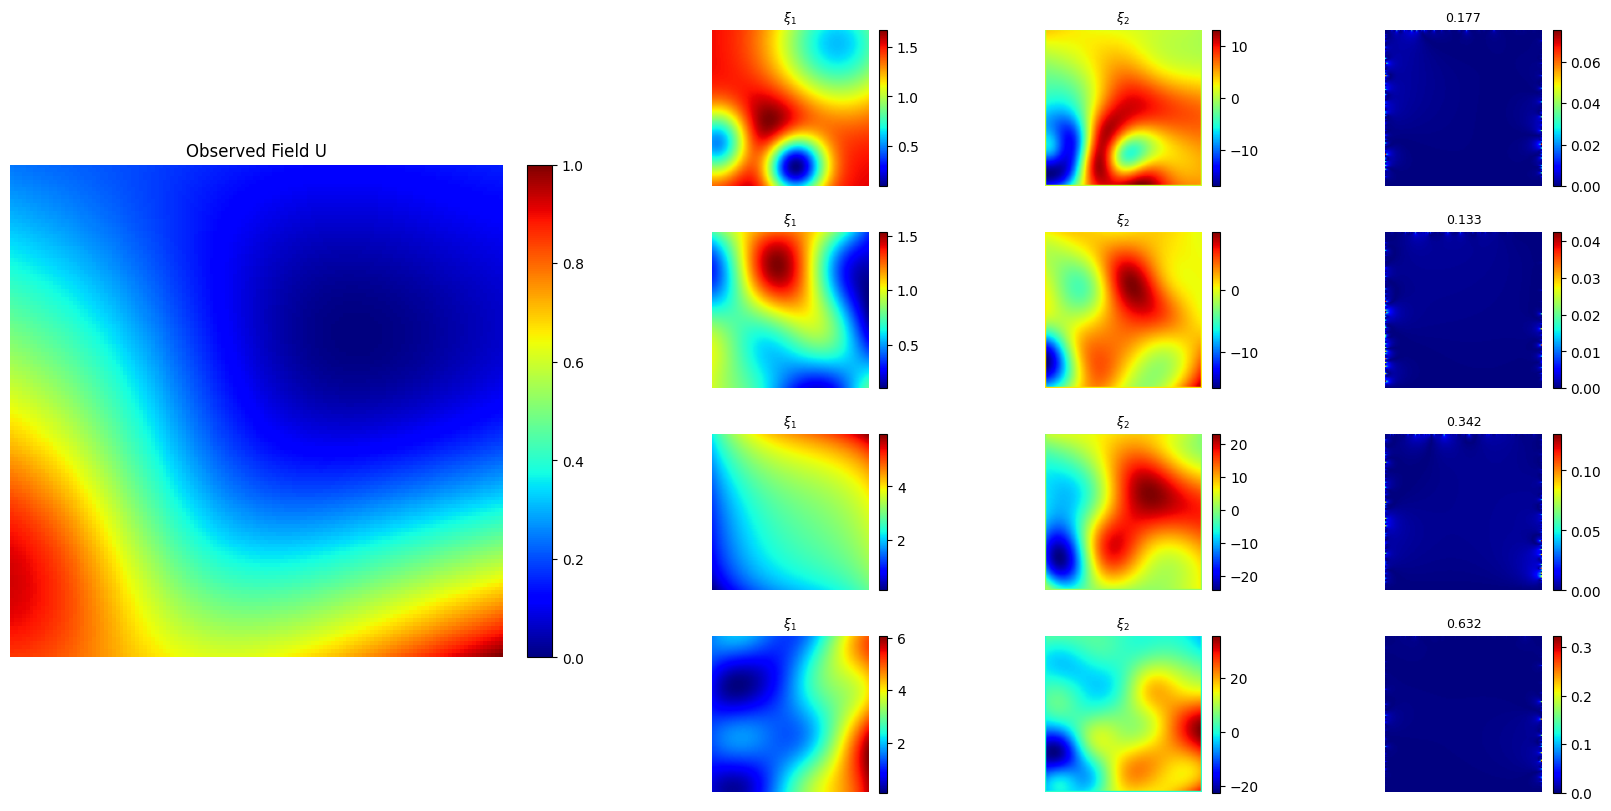

In [8]:
fig = plt.figure(figsize=(16 , 8), constrained_layout = True)
gs = plt.GridSpec(nrows = 4, ncols = 4, figure = fig, width_ratios = [1.8, 1, 1, 1])

# Observation Data U 
ax_left = fig.add_subplot(gs[:, 0])
im0 = ax_left.imshow(U, cmap = 'jet')
fig.colorbar(im0, ax = ax_left, fraction = 0.05, pad = 0.05)
ax_left.set_title("Observed Field U")
ax_left.axis("off")

# Parameters and errors       
axs = []
k = 0
for i in range(4):
    for j in range(1, 4):
        vmin = np.min([np.min(np.asarray(Results[kk][j-1])) for kk in range(4)])
        vmax = np.max([np.max(np.asarray(Results[kk][j-1])) for kk in range(4)])

        ax = fig.add_subplot(gs[i, j])
        data = Results[k][j-1]
        im = ax.imshow(data, cmap = 'jet')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(
            r'$\xi_1$' if j == 1
            else r'$\xi_2$' if j == 2
            else f"{Errors[k]:.3f}",
            fontsize=9
        )

        ax.axis("off")
        axs.append(ax)

    k += 1

plt.show()